In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('DnD.csv')

In [6]:
# Get a sense for what the data looks like

df.head()

# I want to rename some of these stats for clarity

df = df.rename({'stats_1': 'strength', 'stats_2': 'dexterity', 'stats_3': 'constitution', 'stats_4': 'intelligence', 'stats_5': 'wisdom', 'stats_6': 'charisma'}, axis=1)
df.head()

,Unnamed: 0,char_id,name,base_hp,strength,dexterity,constitution,intelligence,wisdom,charisma,...,class_starting_level,subclass_starting,class_other,subclass_other,total_level,feats,inventory,date_modified,notes_len,gold
0,0,1,Molster,8,11,22,11,17,20,12,...,4,NaN,NaN,NaN,4,NaN,Adamantine Chain Shirt/Cloak of Protection/Gog...,2022-09-12T19:13:03.29Z,17,305.00
1,1,3,Prailak,103,12,17,18,14,16,16,...,20,The Great Old One,NaN,NaN,20,"Spell Sniper (Bard, Sorcerer, Warlock)/Inferna...","Bag of Holding/Iron Flask/Studded Leather, +3/...",2021-12-07T21:25:36.9Z,60,0.00
2,2,8,Aurilanax,76,18,10,16,13,13,16,...,7,Oath of the Crown,NaN,NaN,7,NaN,Shield,2021-01-21T16:50:35Z,0,0.00
3,3,10,Gamndell Banglebon,127,10,14,16,16,15,18,...,2,NaN,Bard/Cleric/Wizard,School of Illusion,16,NaN,Give/Studded Leather/Dagger/Light Hammer/Ink (...,2020-08-06T16:05:07Z,65,4951.06
4,4,19,Bellek Bouncer,52,10,10,15,12,14,10,...,6,Life Domain,NaN,NaN,6,NaN,Shield/Plate/Mace/Potion of Healing,2020-05-15T04:47:59Z,0,0.00


In [7]:
# Basic insights

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1204252 entries, 0 to 1204251
Data columns (total 23 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   Unnamed: 0            1204252 non-null  int64  
 1   char_id               1204252 non-null  int64  
 2   name                  1199618 non-null  object 
 3   base_hp               1204252 non-null  int64  
 4   strength              1204252 non-null  int64  
 5   dexterity             1204252 non-null  int64  
 6   constitution          1204252 non-null  int64  
 7   intelligence          1204252 non-null  int64  
 8   wisdom                1204252 non-null  int64  
 9   charisma              1204252 non-null  int64  
 10  background            898870 non-null   object 
 11  race                  1204252 non-null  object 
 12  class_starting        1204252 non-null  object 
 13  class_starting_level  1204252 non-null  int64  
 14  subclass_starting     607804 non-n

In [8]:
# Greater details on the summary statistics

df.describe(include='all')

,Unnamed: 0,char_id,name,base_hp,strength,dexterity,constitution,intelligence,wisdom,charisma,...,class_starting_level,subclass_starting,class_other,subclass_other,total_level,feats,inventory,date_modified,notes_len,gold
count,1.204252e+06,1.204252e+06,1199618,1.204252e+06,1.204252e+06,1.204252e+06,1.204252e+06,1.204252e+06,1.204252e+06,1.204252e+06,...,1.204252e+06,607804,78814,48834,1.204252e+06,219008,832291,1204252,1.204252e+06,1.204252e+06
unique,NaN,NaN,393263,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,997,983,1760,NaN,10990,228330,101591,NaN,NaN
top,NaN,NaN,Test,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,Life Domain,Warlock,The Fiend,NaN,Grappler,Leather/Shortsword/Shortsword/Longbow/Arrows/B...,2018-06-29T15:37:47Z,NaN,NaN
freq,NaN,NaN,1206,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,62269,11229,4213,NaN,63705,9086,960942,NaN,NaN
mean,6.021255e+05,8.760689e+05,NaN,2.347389e+01,1.051853e+01,1.153501e+01,1.146815e+01,1.025950e+01,1.091329e+01,1.066623e+01,...,3.952510e+00,NaN,NaN,NaN,4.209893e+00,NaN,NaN,NaN,2.440385e+02,1.336151e+06
std,3.476378e+05,4.414356e+05,NaN,2.677593e+01,4.829688e+00,4.918547e+00,4.744150e+00,4.565985e+00,4.745979e+00,4.844946e+00,...,4.344063e+00,NaN,NaN,NaN,4.640197e+00,NaN,NaN,NaN,9.688915e+02,1.131455e+08
min,0.000000e+00,1.000000e+00,NaN,-6.240000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.000000e+00,NaN,NaN,NaN,1.000000e+00,NaN,NaN,NaN,-3.264000e+04,0.000000e+00
25%,3.010628e+05,5.446485e+05,NaN,8.000000e+00,8.000000e+00,1.000000e+01,1.100000e+01,8.000000e+00,1.000000e+01,8.000000e+00,...,1.000000e+00,NaN,NaN,NaN,1.000000e+00,NaN,NaN,NaN,0.000000e+00,0.000000e+00
50%,6.021255e+05,8.185030e+05,NaN,1.200000e+01,1.100000e+01,1.300000e+01,1.300000e+01,1.100000e+01,1.200000e+01,1.200000e+01,...,2.000000e+00,NaN,NaN,NaN,2.000000e+00,NaN,NaN,NaN,0.000000e+00,0.000000e+00
75%,9.031882e+05,1.188040e+06,NaN,2.900000e+01,1.400000e+01,1.500000e+01,1.400000e+01,1.300000e+01,1.400000e+01,1.400000e+01,...,5.000000e+00,NaN,NaN,NaN,5.000000e+00,NaN,NaN,NaN,5.300000e+01,2.500000e+01


In [9]:
# Looking for missing data

df.isnull().sum()

# There seems to be many missing data points
# but it's not as simple as it looks

# The Name column is missing values but it's not a very useful variable
# Many more backgrounds are missing since they don't tend to be very valuable. We can assume missing values represent
# people who don't care about them.

# Subclasses are more complex. Many classes don't start with a subclass so it's challenging to tell if they're missing or intentionally blank at a glance.
# other class or the multiclassing option is fairly straightforward. Where inputs are missing it's very possible those characters didn't multiclass and once again not all classes start with a subclass

# feats suffer from being an optional rule, and many characters only begin to get it at 4th level. It could be delayed even further if they multiclassed

# We saw the median starting level was 2 and the 75th percentile was only 5. only 5 of the 14 classes get a subclass by level 2 so this number of missing values is expected
# With the exception of humans using the variant rule (difference between human and variant human not indicated by data), nobody should have a feat before level 4
# Even those who could have picked a feat may have chosen to instead increase their stats making this a difficult variable to know for certain if values are missing from
# And finally inventory. This doesn't indicate very much. It might impact stats however so we may look at it in case of outliers.

Unnamed: 0                    0
char_id                       0
name                       4634
base_hp                       0
strength                      0
dexterity                     0
constitution                  0
intelligence                  0
wisdom                        0
charisma                      0
background               305382
race                          0
class_starting                0
class_starting_level          0
subclass_starting        596448
class_other             1125438
subclass_other          1155418
total_level                   0
feats                    985244
inventory                371961
date_modified                 0
notes_len                     0
gold                          0
dtype: int64

In [10]:
# Normally we would clean the data but based on our knowledge of the game we can be confident those inputes
# were left blank intentionally and are non-numeric. Best to leave the null values as they are.

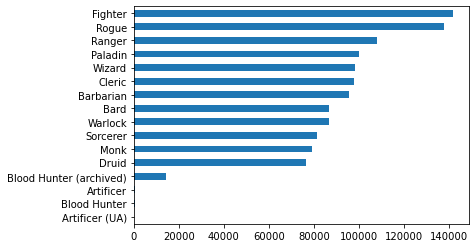

In [11]:
# Let's answer some questions in Python to compare some of the problem solving processes and results

# How popular is each class?

df['class_starting'].value_counts(sort=True).plot(kind="barh")
plt.gca().invert_yaxis()

In [12]:
# Just to look at the raw numbers

df['class_starting'].value_counts(sort=False)

Artificer                     435
Warlock                     86515
Paladin                     99910
Cleric                      97858
Monk                        79001
Barbarian                   95489
Wizard                      98154
Sorcerer                    81233
Fighter                    141664
Rogue                      137773
Bard                        86859
Ranger                     108182
Druid                       76494
Blood Hunter (archived)     14179
Artificer (UA)                103
Blood Hunter                  403
Name: class_starting, dtype: int64

In [13]:
# let's look at feats as well. This is more complex due to the inputs. Let's look at what unique values are there

df["feats"].value_counts()

Grappler                                                       63705
Svirfneblin Magic                                              11740
War Caster                                                      7819
Lucky                                                           5863
Sharpshooter                                                    4809
                                                               ...  
Grappler/Charger/Mage Slayer/Orcish Fury                           1
Sharpshooter/Resilient (Wisdom)/Elven Accuracy                     1
Mobile/Sharpshooter/War Caster                                     1
Healer/Heavily Armored/Svirfneblin Magic/War Caster/Prodigy        1
War Caster/Against All Odds                                        1
Name: feats, Length: 10990, dtype: int64

In [14]:
# It looks like due to the formatting of the data, multiple options being chosen are being considered as a unique
# option rather than being recognized as counting each individual. Luckily they're divided by '/'
# Let's try to look at feats alone and see how popular each feat is.

df_feats = df[df["feats"].notna()]

In [15]:
# I want to seperate out from each input the individual feats

df_feats['feats'].str.split('/',expand=True)

,0,1,2,3,4,5,6,7,8,9,...,93,94,95,96,97,98,99,100,101,102
1,"Spell Sniper (Bard, Sorcerer, Warlock)",Infernal Constitution,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
6,Dual Wielder,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
7,Resilient (Constitution),None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
8,Resilient (Dexterity),Ritual Caster (Wizard),None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
14,Resilient (Intelligence),None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1204236,Fighting Initiate,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
1204243,Great Weapon Master,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
1204245,Grappler,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
1204246,War Caster,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None


In [16]:
# Here I'll flatten the dataframe into an array

feats_array = df_feats['feats'].str.split('/',expand=True).to_numpy()

# Because there are different numbers of feats for each character, many of this data frame had "None" so we'll clean that

feats_array_clean = [[i for i in sublist if i is not None] for sublist in feats_array]

In [17]:
# Now I need to make this nested array into a normal array

feats_array_new = np.concatenate(feats_array_clean)

In [18]:
# We'll turn this into a dataframe so I can use value_counts for easy legibility

feats_df = pd.DataFrame(feats_array_new, columns=['Feats'])

In [19]:
feats_df['Feats'].value_counts(sort=True)

# Here is a major issue with the data: rather than a dropdown menu, users can type whatever they want
# One character had 103 feats, an obvious rule violation. This also allows for misspellings.
# We now know there are 3903 unique values.

Grappler                      68520
War Caster                    18197
Svirfneblin Magic             15423
Lucky                         13535
Tough                         10944
                              ...  
Twin Soul Power                   1
priest)                           1
Plague Rash (Plaguelord           1
Extra 5th Level Spell Slot        1
Def not resilient                 1
Name: Feats, Length: 3903, dtype: int64

In [20]:
feats_df['Feats'].value_counts(sort=True).head(50)

# This at least lets us observe the most common, which is at least interesting, and at most tells us about the sample
# This sample has chosen Grappler many times more than any other feat. This would imply due to the feats weakness
# That most of the users this sample chose from are not building their characters in an optimal way.

Grappler                                  68520
War Caster                                18197
Svirfneblin Magic                         15423
Lucky                                     13535
Tough                                     10944
Sharpshooter                              10316
Alert                                      9866
Observant                                  9257
Great Weapon Master                        8855
Dual Wielder                               8368
Sentinel                                   7803
Mobile                                     7049
Shield Master                              5589
Resilient (Constitution)                   5276
Heavy Armor Master                         4533
Actor                                      4052
Crossbow Expert                            3836
Polearm Master                             3649
Spell Sniper (Bard, Sorcerer, Warlock)     3548
Prodigy                                    3429
Savage Attacker                         

In [21]:
feats_df['Feats'].value_counts(sort=True)[feats_df['Feats'].value_counts(sort=True) > 2].tail(40)

# This lets us see the other end of the spectrum, but rather than observing the least common entries
# We can view some of the slightly more common inputs. Generally speaking this purely to satisfy curiosity.

Arrow Master                              3
*Magic Initiate (Sorcerer)                3
War-caster                                3
Gift of the Archeart                      3
Boon of the Free Fated                    3
Rapid Potion Quaffing                     3
* Improved Monk Features                  3
* Acrobatics (Dexterity skill)            3
Martial Adept ᴿ (Level 4)                 3
Dual Wielder (CJN)                        3
Enchanted Bard Song                       3
Soul-diamond Bond                         3
🏅 Vinethra's Favor                        3
Battlemaster Maneuvers (Other Classes)    3
Battlemaster Maneuvers (Barbarian)        3
Battlemaster Maneuvers (Fighter)          3
DN_Hero Points                            3
Malignitas (Rystall)                      3
Interregnum Travel                        3
WarKaster                                 3
Necrotic Resistance                       3
Astral Projection                         3
Additional Attunement slot      

In [22]:
# Races should be more simple with fewer choices

df['race'].value_counts(sort=False)

# Unexpectedly, this is similar to the challenge I found in feats but still simpler to a degree

Aarakocra        33111
Tiefling         89939
Bugbear           1526
Gnome            44800
Half-Orc         54909
                 ...  
Corgotten            1
Evan's Goblin        1
Nosferatu            2
Gobs                 1
She-wolf             1
Name: race, Length: 1189, dtype: int64

In [23]:
# This is still a useful metric. Most of the top 60 most common races were published by WotC.

df['race'].value_counts(sort=True).head(60)

Human                260467
Elf                  194312
Half-Elf             115163
Dwarf                 89961
Tiefling              89939
Dragonborn            87207
Halfling              60419
Half-Orc              54909
Genasi                48171
Gnome                 44800
Aasimar               43746
Goliath               43105
Aarakocra             33111
Tabaxi                 7090
Tortle                 4155
Firbolg                3145
Kenku                  3012
Lizardfolk             2491
Goblin                 2355
Yuan-ti Pureblood      1896
Bugbear                1526
Feral Tiefling         1483
Kobold (archived)      1431
Triton                 1402
Orc (archived)         1049
Hobgoblin               809
Changeling (UA)         316
Warforged               300
Warforged (UA)          299
Changeling              260
Shifter (UA)            166
Minotaur                166
Kobold                  147
Centaur                 121
Shifter                 112
Lineages            

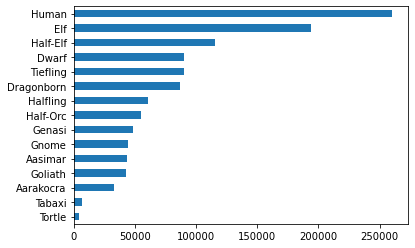

In [24]:
# We can plot the top 15 without losing legibility

df['race'].value_counts(sort=True).head(15).plot(kind="barh")
plt.gca().invert_yaxis()

In [25]:
# I'd like to find out the most common starting subclass, to do that I need to cut all the rows with no subclass

df_class_info = df.dropna(subset=['subclass_starting'])

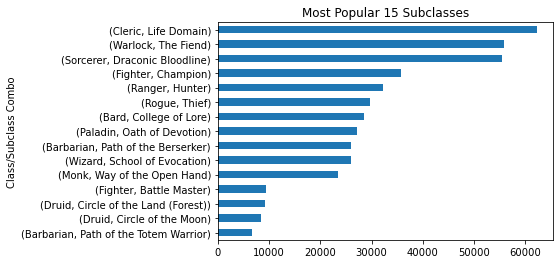

In [26]:
# And here is a sorted list of the most common values

df.groupby(['class_starting', 'subclass_starting']).size().sort_values(ascending=False).head(15).plot(kind="barh")
plt.title("Most Popular 15 Subclasses")
plt.ylabel("Class/Subclass Combo")
plt.gca().invert_yaxis()

In [27]:
# I want to find the most popular subclasses for each class and rank the subclasses by popularity.
# Let's make tables for each class

artificer_ua_df = df[df['class_starting'] == 'Artificer (UA)']#.dropna(subset=['subclass_starting'])
artificer_df = df[df['class_starting'] == 'Artificer']#.dropna(subset=['subclass_starting'])
barbarian_df = df[df['class_starting'] == 'Barbarian']#.dropna(subset=['subclass_starting'])
bard_df = df[df['class_starting'] == 'Bard']#.dropna(subset=['subclass_starting'])
blood_hunter_archived_df = df[df['class_starting'] == 'Blood Hunter (archived)']#.dropna(subset=['subclass_starting'])
blood_hunter_df = df[df['class_starting'] == 'Blood Hunter']#.dropna(subset=['subclass_starting'])
cleric_df = df[df['class_starting'] == 'Cleric']#.dropna(subset=['subclass_starting'])
druid_df = df[df['class_starting'] == 'Druid']#.dropna(subset=['subclass_starting'])
fighter_df = df[df['class_starting'] == 'Fighter']#.dropna(subset=['subclass_starting'])
monk_df = df[df['class_starting'] == 'Monk']#.dropna(subset=['subclass_starting'])
paladin_df = df[df['class_starting'] == 'Paladin']#.dropna(subset=['subclass_starting'])
ranger_df = df[df['class_starting'] == 'Ranger']#.dropna(subset=['subclass_starting'])
rogue_df = df[df['class_starting'] == 'Rogue']#.dropna(subset=['subclass_starting'])
sorcerer_df = df[df['class_starting'] == 'Sorcerer']#.dropna(subset=['subclass_starting'])
warlock_df = df[df['class_starting'] == 'Warlock']#.dropna(subset=['subclass_starting'])
wizard_df = df[df['class_starting'] == 'Wizard']#.dropna(subset=['subclass_starting'])

In [28]:
# Now let's see for each class the popularity ranking of the subclass

artificer_ua_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(15)

subclass_starting
Artillerist (UA)     23
Alchemist (UA)       19
Battle Smith (UA)    18
Archivist (UA)        4
dtype: int64

In [29]:
artificer_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(15)

subclass_starting
Artillerist           102
Battle Smith           93
Armorer                87
Alchemist              35
Armorer (archived)     14
Archivist               1
dtype: int64

In [30]:
barbarian_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(11)

subclass_starting
Path of the Berserker               26018
Path of the Totem Warrior            6626
Path of the Zealot                   1588
Path of the Ancestral Guardian       1404
Path of the Storm Herald             1370
Path of the Battlerager               429
Path of Wild Magic                     63
Path of the Wild Soul (archived)       56
Path of the Beast                      47
Path of the Juggernaut                 11
Path of the Beast (archived)           10
dtype: int64

In [31]:
bard_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(8)

subclass_starting
College of Lore         28580
College of Valor         2444
College of Glamour       2325
College of Swords        1731
College of Whispers      1520
College of Eloquence       88
College of Creation        45
College of Spirits         27
dtype: int64

In [32]:
blood_hunter_archived_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False)

subclass_starting
Order of the Lycan (archived)           2539
Order of the Profane Soul (archived)    1898
Order of the Ghostslayer (archived)     1622
Order of the Mutant (archived)           938
Order of the Dragonslayer                  4
Shadowhunter                               4
Order of the Fiendslayer • HB              3
COPY_OF_Order of the Lycan                 1
COPY_OF_Order of the Profane Soul          1
dtype: int64

In [33]:
blood_hunter_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False)

subclass_starting
Order of the Lycan                 118
Order of the Ghostslayer            78
Order of the Profane Soul (INT)     68
Order of the Mutant                 62
Order of the Profane Soul (WIS)      5
Order of the Grave                   1
Order of the Winter Heart            1
dtype: int64

In [34]:
cleric_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(16)

subclass_starting
Life Domain                   62269
Tempest Domain                 3504
War Domain                     3377
Light Domain                   2109
Forge Domain                   1845
Grave Domain                   1782
Knowledge Domain               1622
Trickery Domain                1432
Death Domain                   1189
Nature Domain                   900
Arcana Domain                   543
Twilight Domain                  91
Order Domain (archived)          33
Peace Domain                     29
Order Domain                     22
Twilight Domain (archived)       19
dtype: int64

In [35]:
druid_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(17)

subclass_starting
Circle of the Land (Forest)       9091
Circle of the Moon                8356
Circle of the Land (Mountain)     3284
Circle of the Land (Coast)        2352
Circle of the Land (Grassland)    2283
Circle of the Land (Underdark)    1860
Circle of the Land (Arctic)       1739
Circle of the Shepherd            1580
Circle of the Land (Swamp)        1366
Circle of Dreams                  1181
Circle of the Land (Desert)        948
Circle of Spores (archived)        544
Circle of Spores                   154
Circle of Stars                     85
Circle of Wildfire                  61
Circle of Wildfire (archived)       56
Circle of the Land                  52
dtype: int64

In [36]:
fighter_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(15)

subclass_starting
Champion                      35707
Battle Master                  9412
Eldritch Knight                4795
Arcane Archer                  1703
Samurai                        1619
Brute (archived)               1148
Cavalier                        972
Gunslinger                      596
Purple Dragon Knight            301
Rune Knight                     111
Echo Knight                      78
Psi Warrior                      50
Rune Knight (archived)           39
Battlemaster                      9
Psychic Warrior (archived)        6
dtype: int64

In [37]:
monk_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(17)

subclass_starting
Way of the Open Hand                      23370
Way of Shadow                              2910
Way of the Four Elements                   2130
Way of the Drunken Master                  1841
Way of the Kensei                          1713
Way of the Sun Soul                        1301
Way of the Long Death                       680
Way of Mercy                                 70
Way of the Astral Self (archived)            68
Way of the Astral Self                       64
Way of the Cobalt Soul                       57
Way of the Ascendant Dragon (Archived)       39
Way of Mercy (archived)                      18
Way of the Ascendant Dragon                  16
Way of Tranquility                           16
Way of the Four Elements: Remastered         14
Way of the Four Elements Remastered           7
dtype: int64

In [38]:
paladin_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(11)

subclass_starting
Oath of Devotion                   27143
Oath of Vengeance                   6607
Oath of the Ancients                3175
Oath of Conquest                    1957
Oath of Redemption                  1054
Oathbreaker                         1035
Oath of the Crown                   1008
Oath of Glory                         75
Oath of the Watchers                  73
Oath of Heroism (archived)            45
Oath of the Watchers (archived)       21
dtype: int64

In [39]:
ranger_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(12)

subclass_starting
Hunter                     32274
Beast Master                4238
Gloom Stalker               2356
Monster Slayer              1716
Horizon Walker              1606
Drakewarden                   60
Fey Wanderer                  43
Swarmkeeper                   33
Drakewarden (Archived)        17
Beast Conclave                16
Fey Wanderer (archived)       14
UA Beast Master                9
dtype: int64

In [40]:
rogue_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(11)

subclass_starting
Thief                       29637
Assassin                     6615
Arcane Trickster             6404
Swashbuckler                 4413
Inquisitive                  1837
Mastermind                   1755
Scout                        1619
Phantom                        91
Soulknife                      79
The Revived (archived)         21
Soulknife (v.2 archived)       11
dtype: int64

In [41]:
sorcerer_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(11)

subclass_starting
Draconic Bloodline           55497
Wild Magic                    5126
Divine Soul                   2078
Storm Sorcery                 2000
Shadow Magic                  1945
Aberrant Mind                   45
Giant Soul (archived)           41
Phoenix Sorcery                 20
Aberrant Mind (archived)        17
Clockwork Soul                  14
Clockwork Soul (archived)       14
dtype: int64

In [42]:
warlock_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(10)

subclass_starting
The Fiend            55832
The Hexblade          4596
The Great Old One     4395
The Archfey           2588
The Celestial         2103
The Undying            881
The Genie               45
The Raven Queen         38
The Fathomless          27
The Undead              18
dtype: int64

In [43]:
wizard_df.dropna(subset=['subclass_starting']).groupby(['subclass_starting']).size().sort_values(ascending=False).head(13)

subclass_starting
School of Evocation               25936
School of Necromancy               2578
School of Divination               2489
School of Abjuration               1782
Bladesinging                       1759
War Magic                          1644
School of Illusion                 1605
School of Conjuration              1575
School of Transmutation            1237
School of Invention (archived)      861
School of Enchantment               850
Chronurgy Magic                      71
Order of Scribes                     49
dtype: int64

In [44]:
df.groupby(['race', 'class_starting']).size().sort_values(ascending=False).head(40)

race        class_starting
Human       Fighter           48740
Elf         Ranger            39965
            Rogue             29863
            Wizard            28762
Human       Rogue             27310
            Paladin           24953
            Wizard            24681
            Cleric            24076
Elf         Druid             23268
Tiefling    Warlock           22984
Dwarf       Cleric            21967
Halfling    Rogue             21332
Half-Orc    Barbarian         20428
Half-Elf    Bard              20077
Human       Ranger            19531
Dwarf       Fighter           19315
Human       Monk              18628
Goliath     Barbarian         18338
Dragonborn  Paladin           18253
Half-Elf    Rogue             15503
Human       Warlock           15363
            Bard              15055
Dragonborn  Fighter           14901
Human       Barbarian         14296
Half-Elf    Warlock           13702
Dwarf       Barbarian         13697
Half-Elf    Sorcerer          13511
G

In [45]:
df_class_info.groupby(['race', 'class_starting','subclass_starting']).size().sort_values(ascending=False).head(40)

race        class_starting  subclass_starting          
Tiefling    Warlock         The Fiend                      16498
Human       Cleric          Life Domain                    15056
Dwarf       Cleric          Life Domain                    14604
Elf         Ranger          Hunter                         12086
Human       Fighter         Champion                       12079
            Warlock         The Fiend                       9523
Half-Elf    Sorcerer        Draconic Bloodline              9020
Tiefling    Sorcerer        Draconic Bloodline              8626
Elf         Sorcerer        Draconic Bloodline              8499
Dragonborn  Sorcerer        Draconic Bloodline              8336
Human       Sorcerer        Draconic Bloodline              8200
Elf         Wizard          School of Evocation             8010
Half-Elf    Warlock         The Fiend                       7758
            Bard            College of Lore                 7493
Elf         Cleric          Life D

In [46]:
# I want to create a new column to see what book is being used the most. Here is the plan:
# Step 1 - Create a column similar to the feats column containing a list of every book used
## Step 1a - Let's create some temporary columns for each variable that could be sourced from a different book (race, class, sublass, multiclass options)
## Step 1b - Combine the columns
# Step 2 - Follow the process of the feats analysis to find the most commonly used book

df_book = df

len(df_book)

1204252

In [47]:
def book_origin_race(race):
    if race in ['Ghostwise Halfling']:
        return "SCAG"
    elif race in ['Duergar','Eladrin','Githyanki','Githzerai', 'Sea Elf', 'Shadar-kai','Svirfneblin']:
        return "Mordenkainen's"
    elif race in ['Aasimar','Bugbear', 'Firbolg','Goblin','Goliath','Hobgoblin','Kenku','Kobold','Lizardfolk','Orc','Tabaxi','Triton','Yuan-Ti Pureblood']:
        return "Volo's"
    elif race in ['Tortle']:
        return "Tortle Package"
    elif race in ['Grung']:
        return "One Grung Above"
    elif race in ['Warforged', 'Shifter','Changeling','Kalashtar']:
        return "WGE"
    elif race in ['Centaur','Loxodon','Minotaur','Simic Hybrid','Vedalken']:
        return "GGR"
    else:
        return "PHB"

# Create a new column using map()
df_book['book 1'] = df['race'].map(book_origin_race)

In [48]:
# If the characater uses an artificer then it's Eberron

def book_origin_class(class_pick):
    if class_pick in ['Artificer']:
        return 'Eberron'
    else:
        return "PHB"

df_book['book 2'] = df['class_starting'].map(book_origin_class)

In [49]:
df_book['book 3'] = df['class_other'].map(book_origin_class)

In [50]:
def book_origin_subclass(subclass):
    if subclass in ['Death Domain','Oathbreaker']:
        return 'DMG'
    elif subclass in ['Arcana Domain','Purple Dragon Knight','Way of the Long Death','Oath of the Crown','Storm Sorcery','The Undying']:
        return "SCAG"
    elif subclass in ['Path of the Ancestral Guardian','Path of the Storm Herald','Path of the Zealot','College of Glamour', 'College of Swords', 'College of Whispers','Forge Domain', 'Grave Domain','Circle of Dreams', 'Circle of the Shepherd','Arcane Archer', 'Cavalier', 'Samurai','Way of the Drunken Master', 'Way of the Kensei', 'Way of the Sun Soul','Oath of Conquest', 'Oath of Redemption','Gloom Stalker', 'Horizon Walker', 'Monster Slayer','Inquisitive', 'Mastermind' , 'Scout', 'Swashbuckler','Divine Soul', 'Shadow Magic', 'Storm Sorcery','The Celestial', 'The Hexblade','War Magic']:
        return "XGE"
    elif subclass in ['Echo Knight','Chronurgy Magic', 'Graviturgy Magic']:
        return "Wildemount"
    elif subclass in ['Alchemist', 'Artillerist', 'Battle Smith', 'Armorer','Path of Wild Magic','Path of the Beast','College of Creation' , 'College of Eloquence','Order Domain', 'Peace Domain' , 'Twilight Domain','Circle of Spores', 'Circle of Wildfire' , 'Circle of the Stars','Psi Warrior' , 'Rune Knight','Way of Mercy' , 'Way of the Astral Self','Oath of Glory', 'Oath of the Watchers','Fey Wanderer' , 'Swarmkeeper','Phantom' , 'Soulknife','Aberrant Mind' , 'Clockwork Soul','The Genie', 'The Fathomless','Bladesinging', 'Order of Scribes']:
        return "Tasha's"
    else:
        return "PHB"

df_book['book 4'] = df['subclass_starting'].map(book_origin_subclass)

In [51]:
df_book['book 5'] = df['subclass_other'].map(book_origin_subclass)

In [52]:
df_book.head(5)

# main challenge is getting these 5 columns into one df (and eliminating duplicates per character) then counting them


,Unnamed: 0,char_id,name,base_hp,strength,dexterity,constitution,intelligence,wisdom,charisma,...,feats,inventory,date_modified,notes_len,gold,book 1,book 2,book 3,book 4,book 5
0,0,1,Molster,8,11,22,11,17,20,12,...,NaN,Adamantine Chain Shirt/Cloak of Protection/Gog...,2022-09-12T19:13:03.29Z,17,305.00,PHB,Eberron,PHB,PHB,PHB
1,1,3,Prailak,103,12,17,18,14,16,16,...,"Spell Sniper (Bard, Sorcerer, Warlock)/Inferna...","Bag of Holding/Iron Flask/Studded Leather, +3/...",2021-12-07T21:25:36.9Z,60,0.00,PHB,PHB,PHB,PHB,PHB
2,2,8,Aurilanax,76,18,10,16,13,13,16,...,NaN,Shield,2021-01-21T16:50:35Z,0,0.00,Volo's,PHB,PHB,SCAG,PHB
3,3,10,Gamndell Banglebon,127,10,14,16,16,15,18,...,NaN,Give/Studded Leather/Dagger/Light Hammer/Ink (...,2020-08-06T16:05:07Z,65,4951.06,PHB,PHB,PHB,PHB,PHB
4,4,19,Bellek Bouncer,52,10,10,15,12,14,10,...,NaN,Shield/Plate/Mace/Potion of Healing,2020-05-15T04:47:59Z,0,0.00,PHB,PHB,PHB,PHB,PHB


In [53]:
# Now I have every book being used for major character building choices
# Next step is to use similar code to the feats except excluding duplicates for each list

all_books_df = df_book[["book 1", "book 2","book 3", "book 4", "book 5"]]

In [54]:
# I want to make an array for the books
# delete all the NULL values

books_array = all_books_df.to_numpy()
books_array_clean = [[i for i in sublist if i is not None] for sublist in books_array]

In [55]:
# Let's delete duplicates in each list

books_array_clean = [list(set(sublist)) for sublist in books_array_clean]

In [56]:
# Flattening the list

books_array_new = np.concatenate(books_array_clean)

In [57]:
books_df = pd.DataFrame(books_array_new, columns=['Books'])

In [58]:
# Here is the percentage of customers using each book. Of course every player is using the players handbook, but
# only a little over 9% are using Volo's and 5% are using Xanathar's. Everything beyond that is incredibly rare.

(books_df['Books'].value_counts(sort=True) / 1204252) 

PHB                1.000000
Volo's             0.090435
XGE                0.051484
SCAG               0.005153
Tasha's            0.003579
Tortle Package     0.003450
DMG                0.002059
WGE                0.000608
Eberron            0.000454
GGR                0.000355
Wildemount         0.000164
Mordenkainen's     0.000075
One Grung Above    0.000027
Name: Books, dtype: float64

In [59]:
# I want to find the total levels of each character so we can see who got to what level. Rather straightforward

df['total_level'].value_counts(sort=True)

1     534837
3     132472
5      96041
2      75333
4      71576
6      50571
20     40023
10     37053
7      34953
8      33525
9      22847
11     15351
12     14478
15     11731
13      8978
14      8685
16      5716
17      4402
18      3745
19      1923
30         4
22         4
34         3
21         1
Name: total_level, dtype: int64

In [60]:
# I'd like to find out what classes make it to late level
# Are we assuming all of these characters are real or more like blueprints people have made
# I think it's safer to assume the latter. Finding the classes with higher level ratios will
# indicate what people enjoy building in theory

# Luckily we have dataframes for each class. Let's use those to find the levels for each.
# One thing to keep in mind for these subsets of our data frames is that these subsets only consider the starting class
# I could expand each subset to include when classes are multiclassed, or limit the question to starting levels
# I'll be considering the question "from what base class do characters climb the highest in level"

artificer_ua_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25     1.0
0.50     6.0
0.75    10.0
Name: total_level, dtype: float64

In [61]:
artificer_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25     3.0
0.50     6.0
0.75    10.0
Name: total_level, dtype: float64

In [62]:
barbarian_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    2.0
0.75    5.0
Name: total_level, dtype: float64

In [63]:
bard_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    3.0
0.75    5.0
Name: total_level, dtype: float64

In [64]:
blood_hunter_archived_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    3.0
0.75    6.0
Name: total_level, dtype: float64

In [65]:
blood_hunter_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25     4.0
0.50     7.0
0.75    11.0
Name: total_level, dtype: float64

In [66]:
cleric_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    2.0
0.75    6.0
Name: total_level, dtype: float64

In [67]:
druid_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    2.0
0.75    5.0
Name: total_level, dtype: float64

In [68]:
fighter_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    3.0
0.75    6.0
Name: total_level, dtype: float64

In [69]:
monk_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    3.0
0.75    6.0
Name: total_level, dtype: float64

In [70]:
paladin_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    3.0
0.75    6.0
Name: total_level, dtype: float64

In [71]:
ranger_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    2.0
0.75    5.0
Name: total_level, dtype: float64

In [72]:
rogue_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    2.0
0.75    5.0
Name: total_level, dtype: float64

In [73]:
sorcerer_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    2.0
0.75    5.0
Name: total_level, dtype: float64

In [74]:
warlock_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    2.0
0.75    5.0
Name: total_level, dtype: float64

In [75]:
wizard_df['total_level'].quantile([0.25, 0.5, 0.75])

0.25    1.0
0.50    2.0
0.75    6.0
Name: total_level, dtype: float64

In [76]:
# Aside from the classes with a much smaller sample size the level spread isn't that different from once class to the other. 
# This could indicate that people are interested equally in building all classes. Or that class isn't a good indicator of level.

In [77]:
df_double_class = df_class_info[~df_class_info['class_other'].str.contains('/', na=True)]

In [78]:
df_double_class.groupby(['class_starting','class_other']).size().sort_values(ascending=False).tail(40)

class_starting           class_other   
Artificer                Rogue             6
Cleric                   Blood Hunter      6
Rogue                    Artificer         6
Sorcerer                 Blood Hunter      5
Barbarian                Blood Hunter      5
Druid                    Artificer (UA)    5
Wizard                   Artificer (UA)    5
Fighter                  Blood Hunter      5
Artificer (UA)           Rogue             5
Blood Hunter (archived)  Bard              5
Artificer                Paladin           4
                         Blood Hunter      4
Sorcerer                 Artificer         4
Bard                     Artificer         4
Ranger                   Artificer         4
Bard                     Bard              4
Fighter                  Artificer (UA)    4
Artificer                Cleric            4
Blood Hunter             Wizard            4
Bard                     Artificer (UA)    3
Artificer (UA)           Bard              3
Warlock        

<AxesSubplot:xlabel='date_modified'>

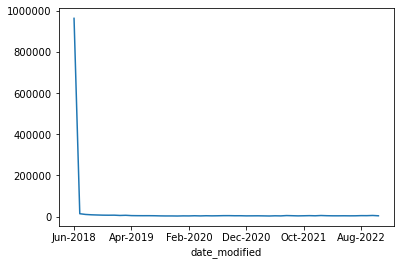

In [79]:
# The last thing I'd like to find is the recency of modifications to the character sheets

df = df.sort_values(by='date_modified')

plt.ticklabel_format(style='plain')
df.groupby(pd.to_datetime(df['date_modified']).dt.strftime('%b-%Y'), sort=False)['char_id'].size().plot()

In [ ]:
# This graph would seem to indicate that the data here was nearly all modified at the same time. I'll continue
# exploring this in detail through further exploration.

In [80]:
pip install psycopg2-binary sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [83]:
# I'm resetting the dataframe so I can send it to SQL

df = pd.read_csv('DnD.csv')
df = df.rename({'stats_1': 'strength', 'stats_2': 'dexterity', 'stats_3': 'constitution', 'stats_4': 'intelligence', 'stats_5': 'wisdom', 'stats_6': 'charisma'}, axis=1)

In [85]:
from sqlalchemy import create_engine

In [86]:
# Connecting to Postgresql

username = # Your Username
password = # Your Password
host = # Your Host
port = '5432'
database = 'dnd_characters'

engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")

# Load DF into SQL

table_name = 'characters'
df.to_sql(table_name, engine, if_exists='replace', index=False)

print(f"Data successfully loaded into table '{table_name}' in database '{database}'.")

Data successfully loaded into table 'characters' in database 'dnd_characters'.
